
# TCGA-GBM RNA-seq: Functional Enrichment and Biological Interpretation

**Author:** Ola Hassan, PhD  
**Project:** TCGA Glioblastoma Transcriptomic Analysis  
**Tools:** Python, PyDESeq2, GSEApy, pandas, Matplotlib, Seaborn

## 1. Introduction

Glioblastoma (GBM) is an aggressive primary brain malignancy characterized by extensive molecular heterogeneity, transcriptional plasticity, and dysregulation of multiple oncogenic signaling pathways.

Differential gene expression analysis provides insight into transcriptional changes between tumor and normal tissue. However, individual gene-level changes do not fully capture coordinated alterations in biological processes.

This notebook extends the PyDESeq2 differential expression analysis by investigating enriched biological processes and molecular pathways.

### Objectives

1. Identify significantly enriched Gene Ontology (GO) biological processes.
2. Perform Gene Set Enrichment Analysis (GSEA) using MSigDB Hallmark gene sets.
3. Investigate Reactome pathways associated with GBM transcriptional alterations.
4. Explore biological programs related to cell proliferation, stemness, chromatin regulation, and epigenetic plasticity.
5. Interpret findings in the context of GBM biology and precision oncology.

### Experimental Comparison

**Exp design
:** GBM tumor versus normal tissue

**Differential expression method:** PyDESeq2

**Significance thresholds:**
- Adjusted p-value < 0.05
- Absolute log2 fold change > 1

### Analysis Strategy

Two complementary enrichment approaches will be used:

**Overrepresentation Analysis (ORA):** Identifies biological processes statistically overrepresented among significantly differentially expressed genes.

**Gene Set Enrichment Analysis (GSEA):** Evaluates whether predefined gene sets show coordinated enrichment toward the top or bottom of a ranked gene list.

Pathway enrichment results will be interpreted as associations with transcriptional differences rather than direct evidence of pathway activity or causal mechanisms.


## 1- Import libraries and define notebook paths

In [18]:


from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gseapy as gp

# Locate the project root
cwd = Path.cwd()

if cwd.name.lower() == "notebooks":
    PROJECT_DIR = cwd.parent
else:
    PROJECT_DIR = cwd

RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = RESULTS_DIR / "figures" / "pathway_analysis"
PATHWAY_DIR = RESULTS_DIR / "pathways"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PATHWAY_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("GSEApy version:", gp.__version__)



Project directory: /Users/olahassan/Desktop/Python/TCGA_GBM
GSEApy version: 1.3.0


## 2- Import saved differential expression results from notebook 3

In [3]:

# Importing DESeq resutls file

RESULTS_FILE = (
    PROJECT_DIR
    / "results"
    / "TCGA_GBM_DESeq2_results_annotated.csv"
)

results = pd.read_csv(
    RESULTS_FILE,
    index_col=0
)

print("Dataset dimensions:", results.shape)
print("\nAvailable columns:")
print(results.columns.tolist())

display(results.head())


Dataset dimensions: (31041, 8)

Available columns:
['baseMean', 'log2FoldChange', 'lfcSE', 'stat', 'pvalue', 'padj', 'gene_symbol', 'Significant']


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,gene_symbol,Significant
ensembl_id,,,,,,,,
ENSG00000000003,1312.786560,1.739160,0.246737,7.048629,1.806892e-12,1.850040e-10,TSPAN6,Upregulated
ENSG00000000419,1009.315667,-0.172767,0.296846,-0.582008,5.605610e-01,6.522868e-01,DPM1,Does not meet thresholds
ENSG00000000457,633.743661,0.310142,0.226656,1.368338,1.712063e-01,2.524114e-01,SCYL3,Does not meet thresholds
ENSG00000000460,256.143060,1.901388,0.359907,5.283005,1.270817e-07,2.992676e-06,C1orf112,Upregulated
ENSG00000000938,406.212573,0.618194,0.353272,1.749909,8.013404e-02,1.355897e-01,FGR,Does not meet thresholds


In [4]:
# validate the results 


required_columns = [
    "log2FoldChange",
    "pvalue",
    "padj"
]

missing = [
    col for col in required_columns
    if col not in results.columns
]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )

print("Total genes:", len(results))
print("Genes with valid adjusted p-values:",
      results["padj"].notna().sum())

print("Significant genes:",
      (results["padj"] < 0.05).sum())

print("Significant genes with |log2FC| > 1:",
      (
          (results["padj"] < 0.05) &
          (results["log2FoldChange"].abs() > 1)
      ).sum())

print("\nGene identifiers (first five):")
print(results.index[:5].tolist())


Total genes: 31041
Genes with valid adjusted p-values: 30614
Significant genes: 14628
Significant genes with |log2FC| > 1: 13202

Gene identifiers (first five):
['ENSG00000000003', 'ENSG00000000419', 'ENSG00000000457', 'ENSG00000000460', 'ENSG00000000938']



## 3. Gene Identifier Preparation and Gene Ranking

Differential expression results generated using PyDESeq2 contain Ensembl gene identifiers, gene symbols, log2 fold changes, Wald statistics, and adjusted p-values.

To support downstream enrichment analyses, genes are organized into three complementary datasets:

1. **Upregulated genes:** Significantly higher expression in GBM tumors compared with normal tissue.
2. **Downregulated genes:** Significantly lower expression in GBM tumors compared with normal tissue.
3. **Ranked gene list:** All genes with valid Wald statistics, ranked by their signed test statistic for Gene Set Enrichment Analysis (GSEA).

For overrepresentation analysis, genes are selected using an adjusted p-value < 0.05 and an absolute log2 fold change > 1.

For preranked GSEA, the signed Wald statistic is used to preserve both the direction and statistical strength of differential expression.

Gene symbols are checked for missing values and duplicates to ensure compatibility with gene-set databases.


### 3.1. Clean and validate gene symbols

In [5]:

# Create a working copy
df = results.copy()

# Clean gene symbols
df["gene_symbol"] = (
    df["gene_symbol"]
    .astype("string")
    .str.strip()
)

# Remove missing or empty gene symbols
df = df.dropna(subset=["gene_symbol"])

df = df[
    (df["gene_symbol"] != "") &
    (~df["gene_symbol"].str.upper().isin(
        ["NA", "NAN", "NONE"]
    ))
].copy()

print("Original genes:", len(results))
print("Genes with valid symbols:", len(df))

# Check duplicate gene symbols
print(
    "Duplicate gene symbols:",
    df["gene_symbol"].duplicated().sum()
)



Original genes: 31041
Genes with valid symbols: 30972
Duplicate gene symbols: 0


In [6]:
# No duplicate gene symbols detected
df_unique = df.copy()

print("Unique gene symbols:", len(df_unique))

Unique gene symbols: 30972


### 3.2. Generate upregulated and downregulated gene lists

In [7]:

# Define thresholds
FDR = 0.05
LFC = 1

# Upregulated genes
upregulated = df_unique[
    (df_unique["padj"] < FDR) &
    (df_unique["log2FoldChange"] > LFC)
].copy()

# Downregulated genes
downregulated = df_unique[
    (df_unique["padj"] < FDR) &
    (df_unique["log2FoldChange"] < -LFC)
].copy()

up_genes = upregulated["gene_symbol"].tolist()
down_genes = downregulated["gene_symbol"].tolist()

print("Upregulated genes:", len(up_genes))
print("Downregulated genes:", len(down_genes))
print("Total selected DEGs:", len(up_genes) + len(down_genes))


Upregulated genes: 8932
Downregulated genes: 4239
Total selected DEGs: 13171


### 3.3. Prepare ranked gene list for GSEA

In [8]:

# Retain all genes with valid Wald statistics
gsea_df = df_unique[
    np.isfinite(df_unique["stat"])
].copy()

# Create ranked gene list
gene_ranking = (
    gsea_df
    .set_index("gene_symbol")["stat"]
    .sort_values(ascending=False)
)

print("Genes available for GSEA:", len(gene_ranking))

print("\nTop positively ranked genes:")
display(gene_ranking.head(10))

print("\nTop negatively ranked genes:")
display(gene_ranking.tail(10))


Genes available for GSEA: 30972

Top positively ranked genes:


gene_symbol
KIF20A     13.151546
RPS3AP6    12.601761
KNL1       12.464383
TOP2A      12.423045
NOX4       12.026629
RRM2       11.802283
RN7SL4P    11.738007
MELK       11.697937
PIMREG     11.377328
NCAPG      11.294769
Name: stat, dtype: float64


Top negatively ranked genes:


gene_symbol
BDNF          -8.276911
GRIPAP1       -8.327829
OTUD7A        -8.530636
AL158212.3    -8.677204
TOM1L2        -8.879669
PRDM2         -9.456645
AC103591.4    -9.733983
ZNNT1        -10.367473
PNPLA7       -10.977015
Z99129.4     -11.022675
Name: stat, dtype: float64

### 3.4. Save gene lists for reproducibility

In [9]:

# Save upregulated genes
upregulated.to_csv(
    PATHWAY_DIR / "GBM_upregulated_genes.csv",
    index=True
)

# Save downregulated genes
downregulated.to_csv(
    PATHWAY_DIR / "GBM_downregulated_genes.csv",
    index=True
)

# Save complete ranked list
gene_ranking.to_csv(
    PATHWAY_DIR / "GBM_GSEA_ranked_genes.rnk",
    sep="\t",
    header=False
)



Gene lists saved successfully.



## 4. Gene Ontology Enrichment Analysis

### 4.1 Biological Process Enrichment

Gene Ontology (GO) enrichment analysis was performed to identify biological processes overrepresented among significantly differentially expressed genes in GBM tumors compared with normal tissue.

Upregulated and downregulated genes were analyzed separetly using GSEApy and the GO Biological Process gene-set library.

The background gene universe was restricted to genes with valid gene symbols that were included in the differential expression testing procedure.

Statistical significance was evaluated using Benjamini-Hochberg-adjusted p-values, with FDR < 0.05.

This analysis aims to identify biological processes associated with transcriptional changes in GBM, including cell proliferation, extracellular matrix remodeling, developmental programs, and chromatin regulation.


### 4.2. Define the gene universe

In [10]:

# Background genes for enrichment analysis
# Exclude genes without a valid differential expression p-value

background_genes = (
    df_unique.loc[
        df_unique["pvalue"].notna(),
        "gene_symbol"
    ]
    .dropna()
    .unique()
    .tolist()
)

print("Background genes:", len(background_genes))
print("Upregulated genes:", len(up_genes))
print("Downregulated genes:", len(down_genes))

assert set(up_genes).issubset(set(background_genes))
assert set(down_genes).issubset(set(background_genes))


Background genes: 30545
Upregulated genes: 8932
Downregulated genes: 4239


### 4.3. Run GO enrichment for upregulated genes

In [15]:


# GO Biological Process enrichment - Upregulated genes

go_up = gp.enrichr(
    gene_list=up_genes,
    gene_sets="GO_Biological_Process_2023",
    organism="human",
    background=background_genes,
    outdir=None,
    cutoff=0.05
)

# Extract enrichment results
go_up_results = go_up.results.copy()

# Sort by adjusted p-value
go_up_results = go_up_results.sort_values(
    "Adjusted P-value"
)

# Filter significant GO terms (FDR < 0.05)
go_up_sig = go_up_results[
    go_up_results["Adjusted P-value"] < 0.05
].copy()

# Summary
print("GO terms tested:", len(go_up_results))
print("Significantly enriched GO terms:", len(go_up_sig))

# Display top 15 significantly enriched GO terms
display(
    go_up_sig[
        [
            "Term",
            "P-value",
            "Adjusted P-value",
            "Odds Ratio",
            "Combined Score",
            "Genes"
        ]
    ].head(15)
)

# Save complete enrichment results
go_up_results.to_csv(
    PATHWAY_DIR / "GO_BP_Upregulated_All.csv",
    index=False
)

# Save significant enrichment results
go_up_sig.to_csv(
    PATHWAY_DIR / "GO_BP_Upregulated_Significant.csv",
    index=False
)



GO terms tested: 4262
Significantly enriched GO terms: 4


,Term,P-value,Adjusted P-value,Odds Ratio,Combined Score,Genes
0,Negative Regulation Of Mitotic Metaphase/Anaph...,0.000027,0.030491,5.11707,53.919447,PLK1;BUB1B;TTK;HASPIN;NDC80;ZWINT;CDC20;MAD2L2...
1,Mitotic Spindle Assembly Checkpoint Signaling ...,0.000029,0.030491,5.45336,57.050387,PLK1;BUB1B;TTK;HASPIN;NDC80;ZWINT;CDC20;MAD2L2...
2,Mitotic Spindle Checkpoint Signaling (GO:0071174),0.000029,0.030491,5.45336,57.050387,PLK1;BUB1B;TTK;HASPIN;NDC80;ZWINT;CDC20;MAD2L2...
3,Spindle Assembly Checkpoint Signaling (GO:0071...,0.000029,0.030491,5.45336,57.050387,PLK1;BUB1B;TTK;HASPIN;NDC80;ZWINT;CDC20;MAD2L2...



GO enrichment results saved successfully.



### Biological Interpretation of Upregulated GO Terms

Gene Ontology Biological Process enrichment analysis identified **4 statistically significant GO terms** among 4,262 tested terms (FDR < 0.05).

All four significant terms were associated with mitotic spindle checkpoint signaling and regulation of the metaphase-to-anaphase transition.

The enriched gene sets included key regulators of mitotic progression and chromosome segregation, including **PLK1, BUB1B, TTK, NDC80, ZWINT, HASPIN, and CDC20**.

These findings suggest that genes involved in mitotic checkpoint regulation are disproportionately represented among transcripts upregulated in GBM tumors relative to normal tissue.

The significant GO terms are highly related and share contributing genes, indicating a common biological enrichment signal rather than four independent functional programs.

**Biological implications:**

- Enrichment of mitotic checkpoint-associated genes is consistent with transcriptional programs involved in cell division.
- Dysregulation of mitotic regulatory machinery may be relevant to the proliferative characteristics of GBM.
- Several contributing genes, including PLK1 and TTK, encode proteins with established roles in mitotic regulation and potential therapeutic relevance.

**Explanation why only 4 GO pathways were enriched:**

Because the DEG list contains a large fraction of the tested genes, many biological processes may be represented in both the DEG list and the background universe.
Overrepresentation analysis asks whether a pathway contains more DEGs than expected given the background, rather than whether many pathway genes are differentially expressed.
With 8,932 upregulated genes among approximately 30,972 genes with valid symbols, broad biological processes may not show strong overrepresentation.
This is one reason why preranked GSEA will be particularly useful for your dataset. It evaluates coordinated changes across the entire ranked gene list instead of depending on a fixed DEG threshold.





In [16]:
### 4.4. Run GO enrichment for downregulated genes


# GO Biological Process enrichment - Downregulated genes

go_down = gp.enrichr(
    gene_list=down_genes,
    gene_sets="GO_Biological_Process_2023",
    organism="human",
    background=background_genes,
    outdir=None,
    cutoff=0.05
)

# Extract enrichment results
go_down_results = go_down.results.copy()

# Sort by adjusted p-value
go_down_results = go_down_results.sort_values(
    "Adjusted P-value"
)

# Filter significant GO terms
go_down_sig = go_down_results[
    go_down_results["Adjusted P-value"] < 0.05
].copy()

# Summary
print("GO terms tested:", len(go_down_results))
print("Significantly enriched GO terms:", len(go_down_sig))

# Display top 15
display(
    go_down_sig[
        [
            "Term",
            "P-value",
            "Adjusted P-value",
            "Odds Ratio",
            "Combined Score",
            "Genes"
        ]
    ].head(15)
)

# Save complete results
go_down_results.to_csv(
    PATHWAY_DIR / "GO_BP_Downregulated_All.csv",
    index=False
)

# Save significant results
go_down_sig.to_csv(
    PATHWAY_DIR / "GO_BP_Downregulated_Significant.csv",
    index=False
)




GO terms tested: 4451
Significantly enriched GO terms: 429


,Term,P-value,Adjusted P-value,Odds Ratio,Combined Score,Genes
0,Chemical Synaptic Transmission (GO:0007268),6.130345e-46,2.728617e-42,6.679087,695.330746,CHRM2;CHRM1;CHRM4;CDH8;CRHBP;GPR176;HTR6;HTR7;...
1,Anterograde Trans-Synaptic Signaling (GO:0098916),4.414620e-38,9.824737e-35,7.453065,641.062788,CHRM2;CHRM1;CHRM4;GPR176;HTR6;HTR7;RPS6KA2;KIF...
2,Monoatomic Cation Transmembrane Transport (GO:...,1.822114e-27,2.703410e-24,4.519836,278.285369,KCNG1;KCNG2;PKD2L1;SLC8A2;ATP6V1E1;SCN1B;SLC39...
3,Inorganic Cation Transmembrane Transport (GO:0...,2.490848e-26,2.771691e-23,4.401488,259.487912,KCNG1;KCNG2;PKD2L1;SLC8A2;ATP6V1E1;SCN1B;SLC39...
4,Potassium Ion Transmembrane Transport (GO:0071...,8.926861e-25,7.946691e-22,7.171315,397.115620,KCNG1;KCNG2;KCNK7;KCNC1;KCNK9;KCNC2;KCNC3;KCNC...
5,Potassium Ion Transport (GO:0006813),1.085130e-23,8.049853e-21,7.539411,398.667166,KCNG1;KCNG2;KCNK7;KCNC1;KCNK9;KCNC2;KCNC3;KCNC...
6,Axonogenesis (GO:0007409),7.225522e-21,4.594400e-18,4.644308,215.387508,CYFIP2;EPHB6;APP;ROBO3;RAB3A;HSP90AB1;MYPN;PPP...
7,Modulation Of Chemical Synaptic Transmission (...,8.363345e-21,4.653156e-18,6.279187,290.289487,APP;MCTP1;CLSTN2;CLSTN3;GRIK5;CLSTN1;DYSF;LRRC...
8,Nervous System Development (GO:0007399),1.107971e-20,5.479532e-18,2.940740,135.124559,CHRM2;APP;SH3GL3;GMFB;CHRM1;MYT1L;ROGDI;ATN1;S...
9,Metal Ion Transport (GO:0030001),1.254010e-19,5.581598e-17,4.954055,215.614201,KCNG1;RYR1;KCNG2;RYR2;KCNK7;KCNC1;KCNK9;KCNC4;...



GO enrichment results saved successfully.



### Biological Interpretation of Downregulated GO Terms

Gene Ontology Biological Process enrichment analysis identified **429 significantly enriched terms among 4,451 tested terms** (FDR < 0.05) within the downregulated gene set.

The most significantly enriched processes were associated with neuronal signaling, synaptic transmission, ion transport, and nervous system development.

**Major enriched biological programs included:**

1. **Synaptic transmission and neuronal communication:** Chemical synaptic transmission (GO:0007268) and anterograde trans-synaptic signaling (GO:0098916) were among the most significantly enriched processes.

2. **Ion channel activity and membrane transport:** Potassium and other cation transport processes were enriched, reflecting reduced expression of multiple neuronal ion-channel-associated genes.

3. **Neuronal development and morphology:** Axonogenesis, axon development, and neuron projection morphogenesis were significantly enriched.

4. **Neurotransmitter signaling:** Neurotransmitter secretion and receptor regulatory processes were enriched among downregulated genes.

### Interpretation

Together, the upregulated and downregulated GO analyses reveal contrasting transcriptional signatures in GBM tumor samples relative to normal brain tissue.

Upregulated genes were enriched for mitotic spindle checkpoint regulation, whereas downregulated genes showed extensive enrichment for neuronal and synaptic functions.

These findings are consistent with differences between proliferative tumor tissue and normal brain tissue containing differentiated neuronal populations.

However, because the analysis uses bulk RNA-seq, differences in cellular composition may contribute substantially to the observed expression patterns.

Consequently, reduced neuronal gene expression should not be interpreted as direct evidence of neuronal dedifferentiation or loss of neuronal identity within GBM tumor cells.

### Biological Implications

The results highlight:

- Enrichment of mitotic regulatory genes among transcripts elevated in GBM.
- Reduced representation of neuronal and synaptic transcriptional programs.
- Potential contributions of tumor heterogeneity and tissue cellular composition.
- The importance of cell-type-aware transcriptomic analyses for interpreting GBM-associated molecular changes.

### Limitations

GO terms are hierarchically related and frequently share genes. Therefore, the 429 significant downregulated terms do not represent 429 independent biological processes.

Additionally, enrichment analysis identifies statistical associations rather than direct evidence of pathway activity or causal mechanisms.

Further investigation using single-cell RNA-seq, spatial transcriptomics, or cell-type deconvolution could help distinguish tumor-intrinsic transcriptional changes from tissue composition effects.


### 4.5. Create a comparative GO enrichment figure

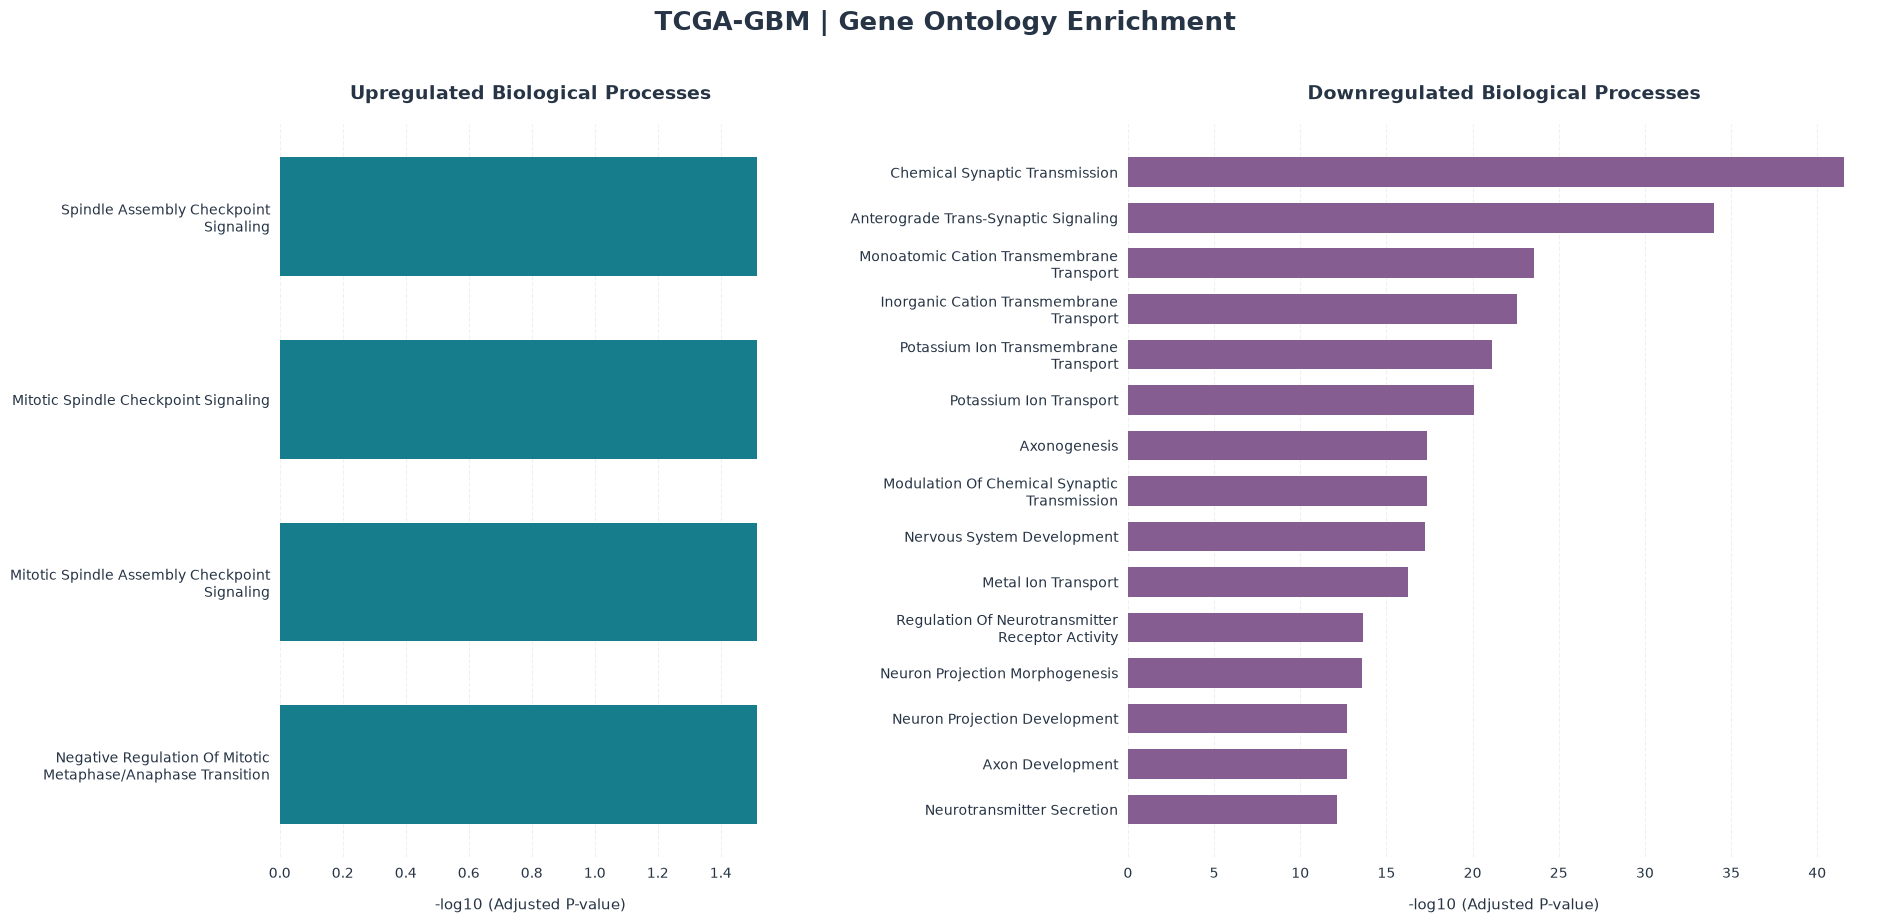

In [20]:

import matplotlib.pyplot as plt
import numpy as np
import textwrap

# Publication-style color palette
UP_COLOR = "#167D8D"       # Deep teal
DOWN_COLOR = "#865D91"     # Muted plum
GRID_COLOR = "#E8EAF0"
TEXT_COLOR = "#263445"

# Prepare significant GO terms
up_plot = go_up_sig.nsmallest(
    4, "Adjusted P-value"
).copy()

down_plot = go_down_sig.nsmallest(
    15, "Adjusted P-value"
).copy()

def prepare_go_plot(df):
    df = df.copy()

    df["minus_log10_FDR"] = -np.log10(
        df["Adjusted P-value"].clip(lower=1e-300)
    )

    df["Term_short"] = (
        df["Term"]
        .str.replace(r"\s*\(GO:\d+\)", "", regex=True)
        .apply(lambda x: textwrap.fill(x, width=36))
    )

    return df.sort_values("minus_log10_FDR")

up_plot = prepare_go_plot(up_plot)
down_plot = prepare_go_plot(down_plot)

# Create figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(19, 9),
    gridspec_kw={"width_ratios": [1, 1.5]}
)

fig.patch.set_facecolor("white")

for ax, data, color, title in zip(
    axes,
    [up_plot, down_plot],
    [UP_COLOR, DOWN_COLOR],
    [
        "Upregulated Biological Processes",
        "Downregulated Biological Processes"
    ]
):
    ax.set_facecolor("white")

    ax.barh(
        data["Term_short"],
        data["minus_log10_FDR"],
        color=color,
        height=0.65,
        edgecolor="none"
    )

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold",
        color=TEXT_COLOR,
        pad=18
    )

    ax.set_xlabel(
        "-log10 (Adjusted P-value)",
        fontsize=11,
        color=TEXT_COLOR,
        labelpad=12
    )

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.7,
        color=GRID_COLOR
    )

    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.tick_params(
        axis="both",
        labelsize=10,
        length=0,
        pad=7,
        colors=TEXT_COLOR
    )

fig.suptitle(
    "TCGA-GBM | Gene Ontology Enrichment",
    fontsize=19,
    fontweight="bold",
    color=TEXT_COLOR,
    y=1.02
)

plt.tight_layout(w_pad=5)

fig.savefig(
    FIGURES_DIR / "GO_BP_Up_vs_Down.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    FIGURES_DIR / "GO_BP_Up_vs_Down.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()



## 5. MSigDB Hallmark Gene Set Enrichment Analysis (GSEA)
- Unlike GO overrepresentation analysis, which uses a predefined DEG cutoff, preranked GSEA evaluates the distribution of genes belonging to a biological pathway across the entire ranked transcriptome.
- We will examine MSigDB Hallmark gene sets, focusing particularly on E2F targets, G2M checkpoint, epithelial–mesenchymal transition (EMT), inflammatory signaling, and other cancer-associated programs.

- ### Ranking Strategy

Genes were ranked using the signed Wald statistic generated by PyDESeq2.

Positive statistics represent higher expression in GBM tumors, while negative statistics represent higher expression in normal tissue, assuming the Tumor versus Normal contrast.

### Biological Objectives

- Identify significantly enriched Hallmark pathways.
- Evaluate cell-cycle-associated transcriptional programs, including E2F targets and G2M checkpoint.
- Investigate epithelial–mesenchymal transition-associated transcriptional signatures.
- Explore inflammatory and immune signaling programs.
- Examine potential relationships between enriched pathways and GBM molecular biology.

### Statistical Interpretation

Normalized enrichment scores (NES) quantify the direction and magnitude of gene-set enrichment after normalization for gene-set size.

Positive NES values indicate enrichment toward the tumor-associated end of the ranked list, whereas negative NES values indicate enrichment toward the normal-associated end.

Enrichment significance is evaluated using FDR-adjusted p-values.

Pathway enrichment is interpreted as evidence of coordinated transcriptional differences, not direct measurement of pathway activation.

### 5.1. Verify your ranked gene list

In [21]:
# Verify ranked gene list for GSEA

print("Total ranked genes:", len(gene_ranking))
print("Unique gene symbols:", gene_ranking.index.nunique())
print("Missing Wald statistics:", gene_ranking.isna().sum())

print(
    "Non-finite statistics:",
    (~np.isfinite(gene_ranking.to_numpy())).sum()
)

print("\nTop positively ranked genes:")
display(gene_ranking.head(10))

print("\nTop negatively ranked genes:")
display(gene_ranking.tail(10))

assert gene_ranking.index.is_unique
assert np.isfinite(gene_ranking.to_numpy()).all()


Total ranked genes: 30972
Unique gene symbols: 30972
Missing Wald statistics: 0
Non-finite statistics: 0

Top positively ranked genes:


gene_symbol
KIF20A     13.151546
RPS3AP6    12.601761
KNL1       12.464383
TOP2A      12.423045
NOX4       12.026629
RRM2       11.802283
RN7SL4P    11.738007
MELK       11.697937
PIMREG     11.377328
NCAPG      11.294769
Name: stat, dtype: float64


Top negatively ranked genes:


gene_symbol
BDNF          -8.276911
GRIPAP1       -8.327829
OTUD7A        -8.530636
AL158212.3    -8.677204
TOM1L2        -8.879669
PRDM2         -9.456645
AC103591.4    -9.733983
ZNNT1        -10.367473
PNPLA7       -10.977015
Z99129.4     -11.022675
Name: stat, dtype: float64

### 5.2 Retrieve MSigDB Hallmark gene sets
We'll use the Hallmark gene-set available through GSEApy.

In [22]:

# Retrieve MSigDB Hallmark gene sets

hallmark_sets = gp.get_library(
    name="MSigDB_Hallmark_2020",
    organism="Human"
)

print("Hallmark gene sets retrieved:", len(hallmark_sets))

print("\nExample gene sets:")
print(list(hallmark_sets.keys())[:10])


Hallmark gene sets retrieved: 50

Example gene sets:
['TNF-alpha Signaling via NF-kB', 'Hypoxia', 'Cholesterol Homeostasis', 'Mitotic Spindle', 'Wnt-beta Catenin Signaling', 'TGF-beta Signaling', 'IL-6/JAK/STAT3 Signaling', 'DNA Repair', 'G2-M Checkpoint', 'Apoptosis']


### 5.3. Run preranked GSEA

In [23]:

# MSigDB Hallmark GSEA using signed Wald statistics

hallmark_gsea = gp.prerank(
    rnk=gene_ranking,
    gene_sets=hallmark_sets,
    min_size=15,  #Excludes very small gene sets
    max_size=500,  #Includes typical Hallmark gene sets
    permutation_num=1000,
    weight=1.0,
    seed=42,
    threads=4,
    outdir=None,
    verbose=True
)

# Extract enrichment results
hallmark_results = hallmark_gsea.res2d.copy()

print("Hallmark gene sets analyzed:", len(hallmark_results))

display(hallmark_results.head())


2026-10-13 16:22:07,595 [WARNING] Duplicated values found in preranked stats: 0.01% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-10-13 16:22:07,596 [INFO] Parsing data files for GSEA.............................
2026-10-13 16:22:07,625 [INFO] 0000 gene_sets have been filtered out when max_size=500 and min_size=15
2026-10-13 16:22:07,626 [INFO] 0050 gene_sets used for further statistical testing.....
2026-10-13 16:22:07,626 [INFO] Start to run GSEA...Might take a while..................
2026-10-13 16:22:09,403 [INFO] Congratulations. GSEApy runs successfully................



Hallmark gene sets analyzed: 50


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,G2-M Checkpoint,0.552663,2.611213,0.0,0.0,0.0,58/200,7.81%,KNL1;TOP2A;NDC80;BUB1;KIF2C;EZH2;UBE2C;PBK;MKI...
1,prerank,KRAS Signaling Dn,-0.424447,-2.491789,0.0,0.0,0.0,74/166,19.43%,MAST3;FGF22;RGS11;NPHS1;SIDT1;MACROH2A2;CAMK1D...
2,prerank,E2F Targets,0.526462,2.489857,0.0,0.0,0.0,56/199,8.31%,TOP2A;RRM2;MELK;DLGAP5;KIF2C;EZH2;MKI67;MYBL2;...
3,prerank,Oxidative Phosphorylation,-0.401057,-2.388619,0.0,0.0,0.0,118/199,35.23%,ACO2;ATP6V1C1;PDP1;MFN2;ATP1B1;ATP6AP1;GOT2;OP...
4,prerank,Estrogen Response Early,-0.375946,-2.217992,0.0,0.0,0.0,60/195,14.63%,MAPT;CYP26B1;ITPK1;TJP3;SYNGR1;FASN;RAPGEFL1;F...


### 5.4 Identify significant Hallmark pathways

In [24]:

# Inspect GSEA output columns
print("Available columns:")
print(hallmark_results.columns.tolist())

# Convert statistical columns to numeric
for col in ["ES", "NES", "NOM p-val", "FDR q-val"]:
    hallmark_results[col] = pd.to_numeric(
        hallmark_results[col],
        errors="coerce"
    )

# Sort by FDR
hallmark_results = hallmark_results.sort_values(
    "FDR q-val"
)

# Filter significant pathways
hallmark_sig = hallmark_results[
    hallmark_results["FDR q-val"] < 0.05  #We'll use FDR < 0.05 as the significance threshold for this analysis.
].copy()

# Separate positive and negative enrichment
hallmark_positive = hallmark_sig[
    hallmark_sig["NES"] > 0
].copy()

hallmark_negative = hallmark_sig[
    hallmark_sig["NES"] < 0
].copy()

print("Total Hallmark pathways:", len(hallmark_results))
print("Significant pathways:", len(hallmark_sig))
print("Positive NES pathways:", len(hallmark_positive))
print("Negative NES pathways:", len(hallmark_negative))

display(
    hallmark_sig[
        ["Term", "ES", "NES", "NOM p-val", "FDR q-val"]
    ].head(20)
)


Available columns:
['Name', 'Term', 'ES', 'NES', 'NOM p-val', 'FDR q-val', 'FWER p-val', 'Tag %', 'Gene %', 'Lead_genes']
Total Hallmark pathways: 50
Significant pathways: 28
Positive NES pathways: 11
Negative NES pathways: 17


,Term,ES,NES,NOM p-val,FDR q-val
0,G2-M Checkpoint,0.552663,2.611213,0.000000,0.000000
1,KRAS Signaling Dn,-0.424447,-2.491789,0.000000,0.000000
2,E2F Targets,0.526462,2.489857,0.000000,0.000000
3,Oxidative Phosphorylation,-0.401057,-2.388619,0.000000,0.000000
4,Estrogen Response Early,-0.375946,-2.217992,0.000000,0.000000
5,heme Metabolism,-0.374889,-2.199336,0.000000,0.000000
7,Myogenesis,-0.340825,-2.015686,0.000000,0.000679
6,UV Response Up,-0.365303,-2.126033,0.000000,0.000815
9,Epithelial Mesenchymal Transition,0.389722,1.851504,0.000000,0.000979
10,Interferon Gamma Response,0.385780,1.831285,0.000000,0.001102


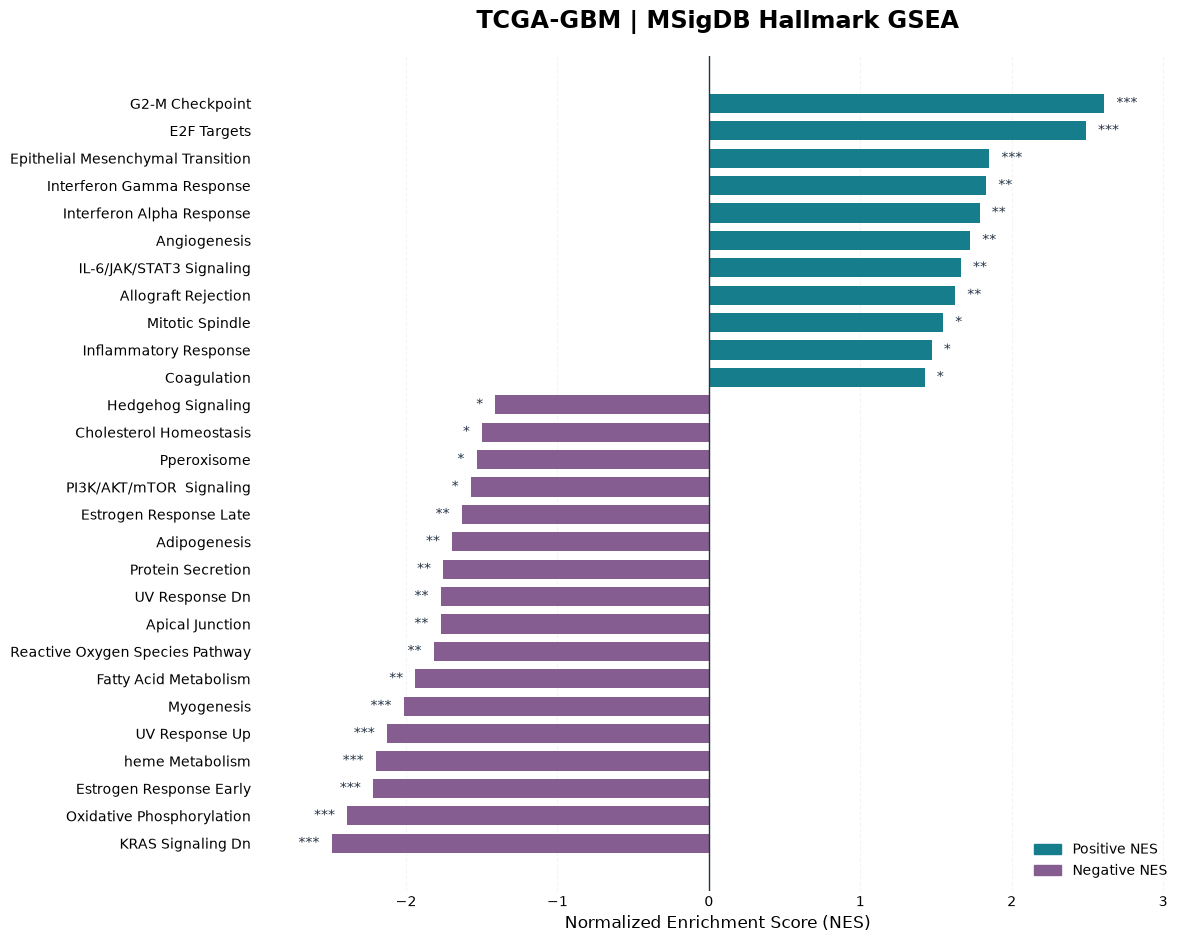

In [33]:
#Hallmark GSEA pathway enrichment plot

import textwrap
from matplotlib.patches import Patch

# Publication-style colors
UP_COLOR = "#167D8D"
DOWN_COLOR = "#865D91"
TEXT_COLOR = "#263445"
GRID_COLOR = "#E8EAF0"

# Select significant Hallmark pathways
hallmark_plot = hallmark_sig.copy()
hallmark_plot = hallmark_plot.sort_values("NES")

# Significance labels
def significance_stars(fdr):
    if fdr < 0.001:
        return "***"
    elif fdr < 0.01:
        return "**"
    elif fdr < 0.05:
        return "*"
    return ""

hallmark_plot["stars"] = hallmark_plot[
    "FDR q-val"
].apply(significance_stars)

colors = [
    UP_COLOR if nes > 0 else DOWN_COLOR
    for nes in hallmark_plot["NES"]
]

# Dynamic figure height
fig_height = max(8, len(hallmark_plot) * 0.34)

fig, ax = plt.subplots(
    figsize=(12, fig_height)
)

ax.barh(
    hallmark_plot["Term"],
    hallmark_plot["NES"],
    color=colors,
    height=0.7
)

# Zero reference
ax.axvline(
    0,
    color=TEXT_COLOR,
    linewidth=1
)

# Significance labels
for i, (_, row) in enumerate(hallmark_plot.iterrows()):
    nes = row["NES"]
    offset = 0.08 if nes > 0 else -0.08

    ax.text(
        nes + offset,
        i,
        row["stars"],
        va="center",
        ha="left" if nes > 0 else "right",
        fontsize=10,
        color=TEXT_COLOR
    )

ax.set_xlabel(
    "Normalized Enrichment Score (NES)",
    fontsize=12
)

ax.set_title(
    "TCGA-GBM | MSigDB Hallmark GSEA",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.5,
    color=GRID_COLOR
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

ax.legend(
    handles=[
        Patch(color=UP_COLOR, label="Positive NES"),
        Patch(color=DOWN_COLOR, label="Negative NES")
    ],
    loc="lower right",
    frameon=False
)

ax.set_xlim(
    hallmark_plot["NES"].min() - 0.5,
    hallmark_plot["NES"].max() + 0.5
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "Hallmark_GSEA_NES.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR / "Hallmark_GSEA_NES.pdf",
    bbox_inches="tight"
)

plt.show()


## Interpretaion: 

**Strong positive enrichment of cell-cycle and proliferation-associated programs including  G2M checkpoint and E2F targets.** 
G2M checkpoint = +2.61NES  
E2F targets =+2.49NES

These are among your strongest positively enriched Hallmark pathways.
They support the earlier GO findings involving PLK1, BUB1B, TTK, CDC20, and spindle checkpoint regulation.
Together, the analyses provide consistent evidence that cell-cycle-associated transcriptional programs are strongly represented among genes elevated in GBM tumors.

### 5.5 — Investigate epigenetic and HDAC7-associated pathways
MSigDB Hallmark contains only 50 broad biological gene sets. It does not provide comprehensive coverage of histone chaperones, chromatin-remodeling complexes, histone methylation, or HDAC7-specific mechanisms. Hence, we will examine downstream transcriptional programs potentially associated with HDAC7 biology, including EMT, E2F targets, G2M checkpoint, MYC signaling, and stemness-related programs. and then we use another GSEA respistory "MSigDB C2 Reactome and C5 GO collections" to investigate specific epigenetic mechanisms, including nucleosome organization, histone modification, chromatin remodeling, and transcriptional regulation.

In [26]:

# Hallmark pathways relevant to epigenetic-associated pathways of interest

epigenetic_hallmarks = {
    "Cell cycle and proliferation": [
        "E2F_TARGETS",
        "G2M_CHECKPOINT",
        "MYC_TARGETS_V1",
        "MYC_TARGETS_V2"
    ],
    "Cellular plasticity and EMT": [
        "EPITHELIAL_MESENCHYMAL_TRANSITION",
        "TGF_BETA_SIGNALING",
        "WNT_BETA_CATENIN_SIGNALING",
        "NOTCH_SIGNALING",
        "HEDGEHOG_SIGNALING"
    ],
    "Stress and survival": [
        "HYPOXIA",
        "P53_PATHWAY",
        "APOPTOSIS",
        "DNA_REPAIR",
        "PI3K_AKT_MTOR_SIGNALING"
    ],
    "Inflammatory signaling": [
        "TNFA_SIGNALING_VIA_NFKB",
        "IL6_JAK_STAT3_SIGNALING",
        "INFLAMMATORY_RESPONSE"
    ]
}

# Match pathways against actual Hallmark results
hallmark_focus = hallmark_results.copy()

hallmark_focus["Term_clean"] = (
    hallmark_focus["Term"]
    .str.upper()
    .str.replace("HALLMARK_", "", regex=False)
    .str.replace(" ", "_", regex=False)
)

pathway_to_category = {
    pathway: category
    for category, pathways in epigenetic_hallmarks.items()
    for pathway in pathways
}

hallmark_focus["Category"] = (
    hallmark_focus["Term_clean"]
    .map(pathway_to_category)
)

hallmark_focus = hallmark_focus.dropna(
    subset=["Category"]
).copy()

hallmark_focus["Significance"] = np.where(
    hallmark_focus["FDR q-val"] < 0.05,
    "Significant",
    "Not significant"
)

display(
    hallmark_focus[
        ["Category", "Term", "NES",
         "FDR q-val", "Significance"]
    ].sort_values("FDR q-val")
)


,Category,Term,NES,FDR q-val,Significance
2,Cell cycle and proliferation,E2F Targets,2.489857,0.000000,Significant
9,Cellular plasticity and EMT,Epithelial Mesenchymal Transition,1.851504,0.000979,Significant
25,Inflammatory signaling,Inflammatory Response,1.471813,0.027424,Significant
27,Cellular plasticity and EMT,Hedgehog Signaling,-1.409836,0.036668,Significant
31,Cell cycle and proliferation,Myc Targets V2,-1.330176,0.057621,Not significant
41,Stress and survival,p53 Pathway,-0.961330,0.623036,Not significant
43,Cellular plasticity and EMT,Notch Signaling,-0.856277,0.845392,Not significant
46,Stress and survival,DNA Repair,-0.753455,0.949424,Not significant
44,Stress and survival,Hypoxia,0.848774,0.953102,Not significant
49,Cell cycle and proliferation,Myc Targets V1,0.429142,0.999953,Not significant


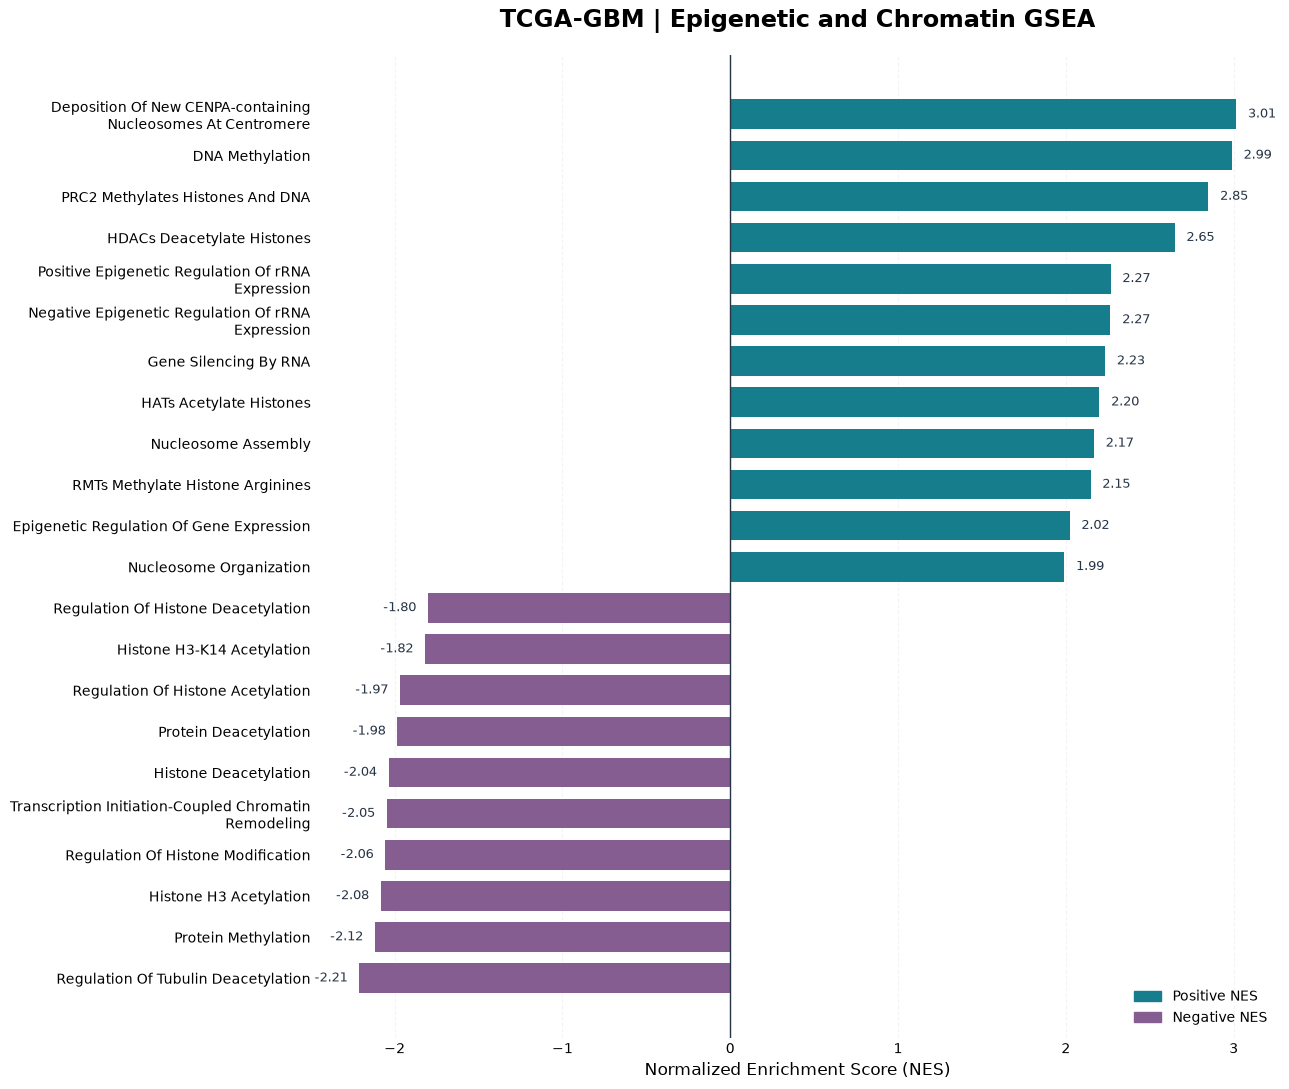

In [34]:
# Epigenetic and chromatin-related GSEA plot


# Select top significant epigenetic pathways
epigenetic_plot = epigenetic_sig.copy()

# Top 12 positive and top 10 negative pathways
positive_epi = (
    epigenetic_plot[epigenetic_plot["NES"] > 0]
    .nlargest(12, "NES")
)

negative_epi = (
    epigenetic_plot[epigenetic_plot["NES"] < 0]
    .nsmallest(10, "NES")
)

epi_plot = pd.concat(
    [positive_epi, negative_epi]
).sort_values("NES")

# Clean pathway labels
epi_plot["Label"] = (
    epi_plot["Term"]
    .str.replace(r"^(Reactome|GO)__", "", regex=True)
    .str.replace(r"\s+R-HSA-\d+$", "", regex=True)
    .str.replace(r"\s+\(GO:\d+\)$", "", regex=True)
    .apply(lambda x: textwrap.fill(x, width=44))
)

colors = [
    UP_COLOR if nes > 0 else DOWN_COLOR
    for nes in epi_plot["NES"]
]

fig, ax = plt.subplots(
    figsize=(13, 11)
)

ax.barh(
    epi_plot["Label"],
    epi_plot["NES"],
    color=colors,
    height=0.72
)

ax.axvline(
    0,
    color=TEXT_COLOR,
    linewidth=1
)

# Add NES values
for i, (_, row) in enumerate(epi_plot.iterrows()):
    nes = row["NES"]

    ax.text(
        nes + (0.07 if nes > 0 else -0.07),
        i,
        f"{nes:.2f}",
        va="center",
        ha="left" if nes > 0 else "right",
        fontsize=9,
        color=TEXT_COLOR
    )

ax.set_title(
    "TCGA-GBM | Epigenetic and Chromatin GSEA",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Normalized Enrichment Score (NES)",
    fontsize=12
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.5,
    color=GRID_COLOR
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

ax.legend(
    handles=[
        Patch(color=UP_COLOR, label="Positive NES"),
        Patch(color=DOWN_COLOR, label="Negative NES")
    ],
    loc="lower right",
    frameon=False
)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "Epigenetic_GSEA_NES.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    FIGURES_DIR / "Epigenetic_GSEA_NES.pdf",
    bbox_inches="tight"
)

plt.show()



## Interpretation

**Strong enrichment towards mesenchymal and inflammatory signaling, including EMT, interferon responses, angiogenesis, and IL-6/JAK/STAT3 signaling.**

The EMT Hallmark signature reflects mesenchymal-like tumor states, extracellular matrix remodeling, or stromal and inflammatory contributions. Similarly, interferon and inflammatory gene sets may reflect tumor cells, infiltrating immune cells.

### 5.6. Add a dedicated chromatin and epigenetic GSEA
The MSigDB C2 Reactome and C5 GO collections provide more mechanistically specific gene sets. Reactome explicitly annotates chromatin-modifying enzymes, histone deacetylation, and histone methylation pathways

#### 5.6.1 Retrieve epigenetic gene sets

In [27]:

# Retrieve detailed pathway collections

reactome_sets = gp.get_library(
    name="Reactome_2022",
    organism="Human"
)

go_bp_sets = gp.get_library(
    name="GO_Biological_Process_2023",
    organism="Human"
)

print("Reactome pathways:", len(reactome_sets))
print("GO biological processes:", len(go_bp_sets))


Reactome pathways: 1816
GO biological processes: 5406


#### 5.7.2 Select chromatin-related pathways

In [28]:

# Keywords covering epigenetic regulatory mechanisms

epigenetic_keywords = [
    "chromatin",
    "nucleosome",
    "histone",
    "methylation",
    "acetylation",
    "deacetylation",
    "heterochromatin",
    "polycomb",
    "remodeling",
    "remodelling",
    "epigenetic",
    "silencing"
]

def select_epigenetic_sets(gene_sets, prefix):
    selected = {}

    for name, genes in gene_sets.items():
        if any(
            keyword in name.lower()
            for keyword in epigenetic_keywords
        ):
            selected[f"{prefix}__{name}"] = genes

    return selected

reactome_epigenetic = select_epigenetic_sets(
    reactome_sets, "Reactome"
)

go_epigenetic = select_epigenetic_sets(
    go_bp_sets, "GO"
)

epigenetic_sets = {
    **reactome_epigenetic,
    **go_epigenetic
}

print("Selected Reactome sets:", len(reactome_epigenetic))
print("Selected GO sets:", len(go_epigenetic))
print("Total epigenetic gene sets:", len(epigenetic_sets))

display(
    pd.DataFrame({
        "Gene Set": list(epigenetic_sets.keys()),
        "Gene Count": [
            len(genes)
            for genes in epigenetic_sets.values()
        ]
    })
)


Selected Reactome sets: 41
Selected GO sets: 131
Total epigenetic gene sets: 172


,Gene Set,Gene Count
0,Reactome__Acyl Chain Remodeling Of CL R-HSA-14...,6
1,Reactome__Acyl Chain Remodeling Of DAG And TAG...,7
2,Reactome__Acyl Chain Remodelling Of PC R-HSA-1...,27
3,Reactome__Acyl Chain Remodelling Of PE R-HSA-1...,29
4,Reactome__Acyl Chain Remodelling Of PG R-HSA-1...,18
...,...,...
167,GO__Subtelomeric Heterochromatin Formation (GO...,5
168,GO__tRNA Methylation (GO:0030488),36
169,GO__Transcription Initiation-Coupled Chromatin...,34
170,GO__Triglyceride-Rich Lipoprotein Particle Rem...,8


#### 5.7.3 Run epigenetic-focused GSEA

In [29]:

# Epigenetic and chromatin-focused GSEA

epigenetic_gsea = gp.prerank(
    rnk=gene_ranking,
    gene_sets=epigenetic_sets,
    min_size=10,
    max_size=500,
    permutation_num=1000,
    weight=1.0,
    seed=42,
    threads=4,
    outdir=None,
    verbose=True
)

epigenetic_results = epigenetic_gsea.res2d.copy()

for col in ["ES", "NES", "NOM p-val", "FDR q-val"]:
    epigenetic_results[col] = pd.to_numeric(
        epigenetic_results[col],
        errors="coerce"
    )

epigenetic_results = epigenetic_results.sort_values(
    "FDR q-val"
)

epigenetic_sig = epigenetic_results[
    epigenetic_results["FDR q-val"] < 0.05
].copy()

print("Pathways analyzed:", len(epigenetic_results))
print("Significant epigenetic pathways:", len(epigenetic_sig))

display(
    epigenetic_results[
        ["Term", "NES", "NOM p-val", "FDR q-val"]
    ].head(25)
)


2026-10-14 15:12:22,345 [WARNING] Duplicated values found in preranked stats: 0.01% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-10-14 15:12:22,345 [INFO] Parsing data files for GSEA.............................
2026-10-14 15:12:22,382 [INFO] 0061 gene_sets have been filtered out when max_size=500 and min_size=10
2026-10-14 15:12:22,382 [INFO] 0111 gene_sets used for further statistical testing.....
2026-10-14 15:12:22,382 [INFO] Start to run GSEA...Might take a while..................
2026-10-14 15:12:25,163 [INFO] Congratulations. GSEApy runs successfully................



Pathways analyzed: 111
Significant epigenetic pathways: 26


,Term,NES,NOM p-val,FDR q-val
0,Reactome__Deposition Of New CENPA-containing N...,3.014670,0.000000,0.000000
1,Reactome__DNA Methylation R-HSA-5334118,2.989045,0.000000,0.000000
2,Reactome__PRC2 Methylates Histones And DNA R-H...,2.848841,0.000000,0.000000
3,Reactome__HDACs Deacetylate Histones R-HSA-321...,2.648131,0.000000,0.000000
4,Reactome__Positive Epigenetic Regulation Of rR...,2.266669,0.000000,0.000000
5,Reactome__Negative Epigenetic Regulation Of rR...,2.265491,0.000000,0.000000
6,Reactome__Gene Silencing By RNA R-HSA-211000,2.233678,0.000000,0.000000
8,Reactome__HATs Acetylate Histones R-HSA-3214847,2.199746,0.000000,0.000000
10,Reactome__RMTs Methylate Histone Arginines R-H...,2.146904,0.000000,0.000000
16,Reactome__Epigenetic Regulation Of Gene Expres...,2.022318,0.000000,0.000000


## Interpretation:

A signigicant enrichment for chromatin and epigenetic regulation, including PRC2-associated methylation, DNA methylation, nucleosome assembly, and histone-modifying enzyme gene sets.

- CENPA deposition and nucleosome assembly: Strong positive enrichment suggests increased representation of genes involved in centromeric chromatin organization and nucleosome dynamics. However, these processes overlap substantially with cell-cycle biology, so their enrichment may partly reflect the strong proliferation signature.
- PRC2-associated methylation: The positive NES of +2.85 is relevant to Polycomb-associated epigenetic regulation, including the machinery responsible for H3K27 methylation. It does not establish increased H3K27me3 abundance or PRC2 catalytic activity.
- HDAC-associated histone deacetylation: The Reactome gene set is positively enriched.
- DNA methylation: Positive enrichment of a DNA methylation-related gene set suggests transcriptional differences in genes annotated to that pathway, not a measurement of DNA methylation levels.

#### 5.8 Save all results

In [31]:

# Save complete Hallmark GSEA results
hallmark_results.to_csv(
    PATHWAY_DIR / "Hallmark_GSEA_All.csv",
    index=False
)

# Save significant pathways
hallmark_sig.to_csv(
    PATHWAY_DIR / "Hallmark_GSEA_Significant.csv",
    index=False
)

# Save positive and negative enrichment separately
hallmark_positive.to_csv(
    PATHWAY_DIR / "Hallmark_GSEA_Positive_NES.csv",
    index=False
)

hallmark_negative.to_csv(
    PATHWAY_DIR / "Hallmark_GSEA_Negative_NES.csv",
    index=False
)


epigenetic_results.to_csv(
    PATHWAY_DIR / "Epigenetic_GSEA_All.csv",
    index=False
)

epigenetic_sig.to_csv(
    PATHWAY_DIR / "Epigenetic_GSEA_Significant.csv",
    index=False
)




Epigenetic GSEA results saved.
Hallmark GSEA results saved successfully.


### 5.9 — Extract epigenetic leading genes
This will help answer three questions:
- Are the PRC2 and HDAC pathway enrichments driven by known chromatin regulators?
- Do the positive Reactome and negative GO histone deacetylation pathways contain different genes?
- Are key HDAC7-associated regulators represented among the leading-edge genes?

In [32]:

# Examine genes driving epigenetic pathway enrichment

selected_terms = [
    "CENPA",
    "DNA METHYLATION",
    "PRC2",
    "HDACS DEACETYLATE",
    "HISTONE DEACETYLATION",
    "NUCLEOSOME ASSEMBLY",
    "NUCLEOSOME ORGANIZATION",
    "HISTONE H3 ACETYLATION"
]

# Select pathways of interest
leading_edge_results = epigenetic_results[
    epigenetic_results["Term"].str.upper().apply(
        lambda x: any(term in x for term in selected_terms)
    )
].copy()

# Extract leading-edge genes
leading_edge_results["Leading_edge_genes"] = (
    leading_edge_results["Lead_genes"]
    .fillna("")
    .str.replace(";", ", ", regex=False)
)

display(
    leading_edge_results[
        [
            "Term",
            "NES",
            "FDR q-val",
            "Leading_edge_genes"
        ]
    ].sort_values("FDR q-val")
)

# Save results
leading_edge_results.to_csv(
    PATHWAY_DIR / "Epigenetic_GSEA_Leading_Edge.csv",
    index=False
)


,Term,NES,FDR q-val,Leading_edge_genes
0,Reactome__Deposition Of New CENPA-containing N...,3.014670,0.000000,"KNL1, H2BC17, HJURP, H2BC9, H2BC11, CENPA, H2A..."
1,Reactome__DNA Methylation R-HSA-5334118,2.989045,0.000000,"H2BC17, H2BC9, H2BC11, H2AC20, H2AC4, H2BC4, H..."
2,Reactome__PRC2 Methylates Histones And DNA R-H...,2.848841,0.000000,"H2BC17, EZH2, H2BC9, H2BC11, H2AC20, H2AC4, H2..."
3,Reactome__HDACs Deacetylate Histones R-HSA-321...,2.648131,0.000000,"H2BC17, H2AC11, H2BC9, H2BC11, H2AC20, H2AC4, ..."
9,GO__Nucleosome Assembly (GO:0006334),2.167163,0.000462,"H2BC17, H2BC9, H2BC11, ASF1B, H2BC8, H3C1, H2B..."
17,GO__Nucleosome Organization (GO:0034728),1.991021,0.002312,"H2BC17, H2BC9, H2BC11, ASF1B, H2BC8, H3C1, H2B..."
15,GO__Histone Deacetylation (GO:0016575),-2.035996,0.013293,"HDAC5, HDAC11, CHD3, MTA3, BRMS1L, SUDS3, MTA1..."
12,GO__Histone H3 Acetylation (GO:0043966),-2.082529,0.014770,"ATXN7L3, TADA2B, LDB1, KAT14, KAT2A, SUPT7L, W..."
22,GO__Regulation Of Histone Deacetylation (GO:00...,-1.801400,0.048297,"KAT14, KAT2A, FOXP3, WDR5, CTBP1, ING2, MBIP, ..."
52,GO__Positive Regulation Of DNA Methylation-Dep...,-1.191013,0.407325,MPHOSPH8


### Interpretation:

#### What is driving the epigenetic enrichment in GBM?
The strongest positively enriched Reactome epigenetic pathways appear to be driven substantially by canonical histone genes, whereas negatively enriched GO histone-modification pathways contain a different collection of chromatin-regulatory enzymes and complexes.
This helps explain why Reactome histone deacetylation is positively enriched while GO histone deacetylation is negatively enriched.

We have here three major biological patterns:

**A. Histone expression and nucleosome assembly**
The strongest positively enriched pathways include:
Pathway	NES	Representative leading-edge genes
CENPA nucleosome deposition	(+3.01), DNA methylation (Reactome)	(+2.99), PRC2 methylation (+2.85), HDAC histone deacetylation (+2.65),	
Nucleosome assembly	(+2.17)	
The repeated appearance of H2BC17, H2BC9, H2BC11, and H2AC20 across multiple pathways is especially important.
These genes encode canonical histone proteins, which are involved in nucleosome assembly, that is essentially needed during DNA replication and cell-cycle progression.
Therefore, the enrichment of Reactome DNA methylation, PRC2, and HDAC-associated gene sets may partly reflect a shared histone and proliferation-associated transcriptional program, rather than independent increases in DNA methylation, PRC2 activity, and histone deacetylation.This is also supported by the strong Hallmark G2M and E2F enrichment.


**B. Epigenetic regulators and chromatin-modifying complexes**
Some pathways also contain more mechanistically informative genes.
Gene	Relevance
EZH2	Catalytic component of PRC2, associated with H3K27 methylation
ASF1B	Histone H3–H4 chaperone involved in nucleosome assembly
HJURP	Histone chaperone involved in CENP-A deposition
CENPA	Centromeric histone H3 variant
CHD3	ATP-dependent chromatin remodeling and NuRD-associated regulation
MTA1 / MTA3	NuRD complex-associated transcriptional regulation
HDAC5 / HDAC11	Histone deacetylase family members
KAT2A / KAT14	Histone acetyltransferase-associated functions
Of particular interest to your research is ASF1B, which is involved in histone chaperoning, although its function should not be equated with HDAC7-dependent H3.3 regulation.

**C. Opposite directions of histone deacetylation enrichment**
Reactome: HDACs deacetylate histones (NES +2.65), GO: Histone deacetylation (NES −2.04).
The two annotations are not interchangeable. The Reactome enrichment appears strongly influenced by histone substrate genes, whereas the GO enrichment includes several enzymes and regulatory-complex components.

These findings support the broader importance of chromatin-associated transcriptional programs in GBM.

In [35]:
# Individual GSEA enrichment curves


from gseapy import gseaplot

# Inspect available Hallmark pathways
print("Hallmark pathways:")
print(list(hallmark_gsea.results.keys())[:10])

print("\nEpigenetic pathways:")
print(list(epigenetic_gsea.results.keys())[:10])


Hallmark pathways:
['Unfolded Protein Response', 'Epithelial Mesenchymal Transition', 'Pancreas Beta Cells', 'heme Metabolism', 'Myc Targets V2', 'Angiogenesis', 'Interferon Alpha Response', 'IL-6/JAK/STAT3 Signaling', 'Myogenesis', 'Adipogenesis']

Epigenetic pathways:
['Reactome__SUMOylation Of DNA Methylation Proteins R-HSA-4655427', 'GO__Histone H2A Acetylation (GO:0043968)', 'GO__Histone Modification (GO:0016570)', 'GO__Regulation Of Tissue Remodeling (GO:0034103)', 'GO__Histone Deubiquitination (GO:0016578)', 'GO__Histone Monoubiquitination (GO:0010390)', 'GO__Positive Regulation Of Histone H3-K4 Methylation (GO:0051571)', 'GO__Histone H3 Acetylation (GO:0043966)', 'GO__Positive Regulation Of Heterochromatin Formation (GO:0031453)', 'GO__N-terminal Protein Amino Acid Acetylation (GO:0006474)']


Generating: G2-M Checkpoint


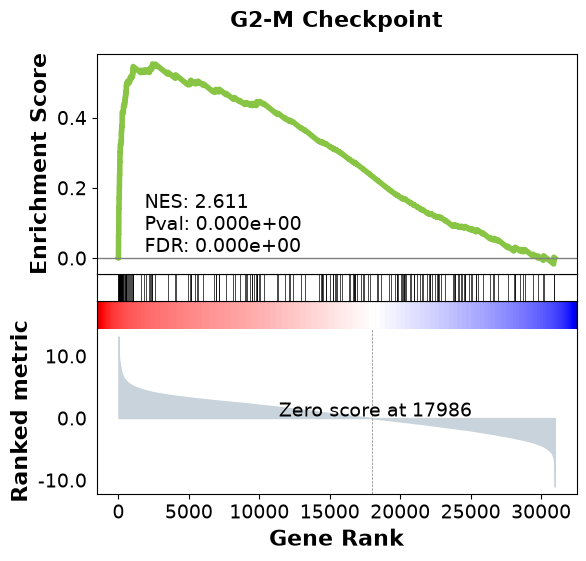

Generating: Epithelial Mesenchymal Transition


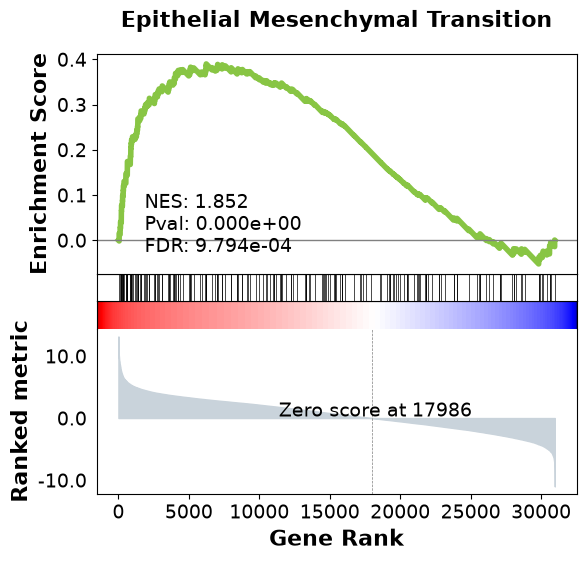

Generating: Reactome__PRC2 Methylates Histones And DNA R-HSA-212300


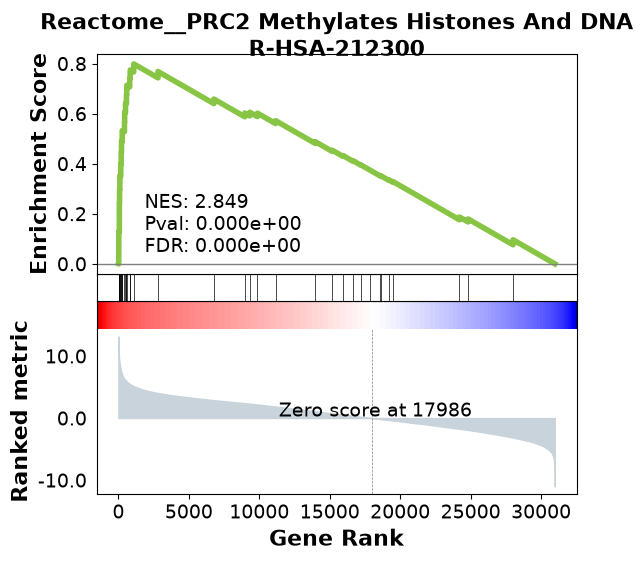

Generating: Reactome__HDACs Deacetylate Histones R-HSA-3214815


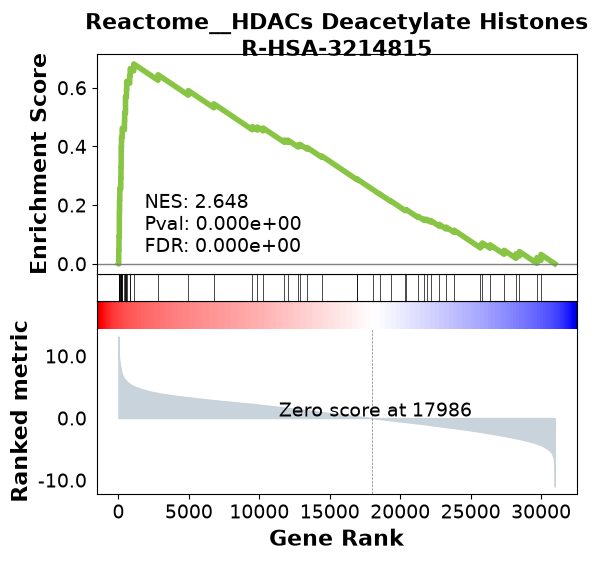

In [36]:

# Helper function for GSEA enrichment plots

def save_gsea_plot(gsea_object, term, filename):

    if term not in gsea_object.results:
        print(f"Pathway not found: {term}")
        return

    result = gsea_object.results[term]

    axes = gseaplot(
        rank_metric=gsea_object.ranking,
        term=term,
        **result
    )

    # GSEApy returns plot axes or an axes collection
    # depending on the installed version.
    if isinstance(axes, list):
        fig = axes[0].figure
    elif hasattr(axes, "figure"):
        fig = axes.figure
    else:
        fig = plt.gcf()

    fig.savefig(
        FIGURES_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

    fig.savefig(
        FIGURES_DIR / f"{filename}.pdf",
        bbox_inches="tight"
    )

    plt.show()

# Find exact pathway names dynamically
def find_pathway(gsea_object, keyword):
    matches = [
        term for term in gsea_object.results
        if keyword.lower() in term.lower()
    ]
    return matches[0] if matches else None

plot_targets = [
    (
        hallmark_gsea,
        "G2-M Checkpoint",
        "GSEA_G2M_Checkpoint"
    ),
    (
        hallmark_gsea,
        "Epithelial Mesenchymal Transition",
        "GSEA_EMT"
    ),
    (
        epigenetic_gsea,
        "PRC2 Methylates",
        "GSEA_PRC2"
    ),
    (
        epigenetic_gsea,
        "HDACs Deacetylate",
        "GSEA_HDAC_Deacetylation"
    )
]

for gsea_obj, keyword, filename in plot_targets:

    term = find_pathway(gsea_obj, keyword)

    if term:
        print(f"Generating: {term}")
        save_gsea_plot(
            gsea_obj,
            term,
            filename
        )
    else:
        print(f"No pathway matched: {keyword}")


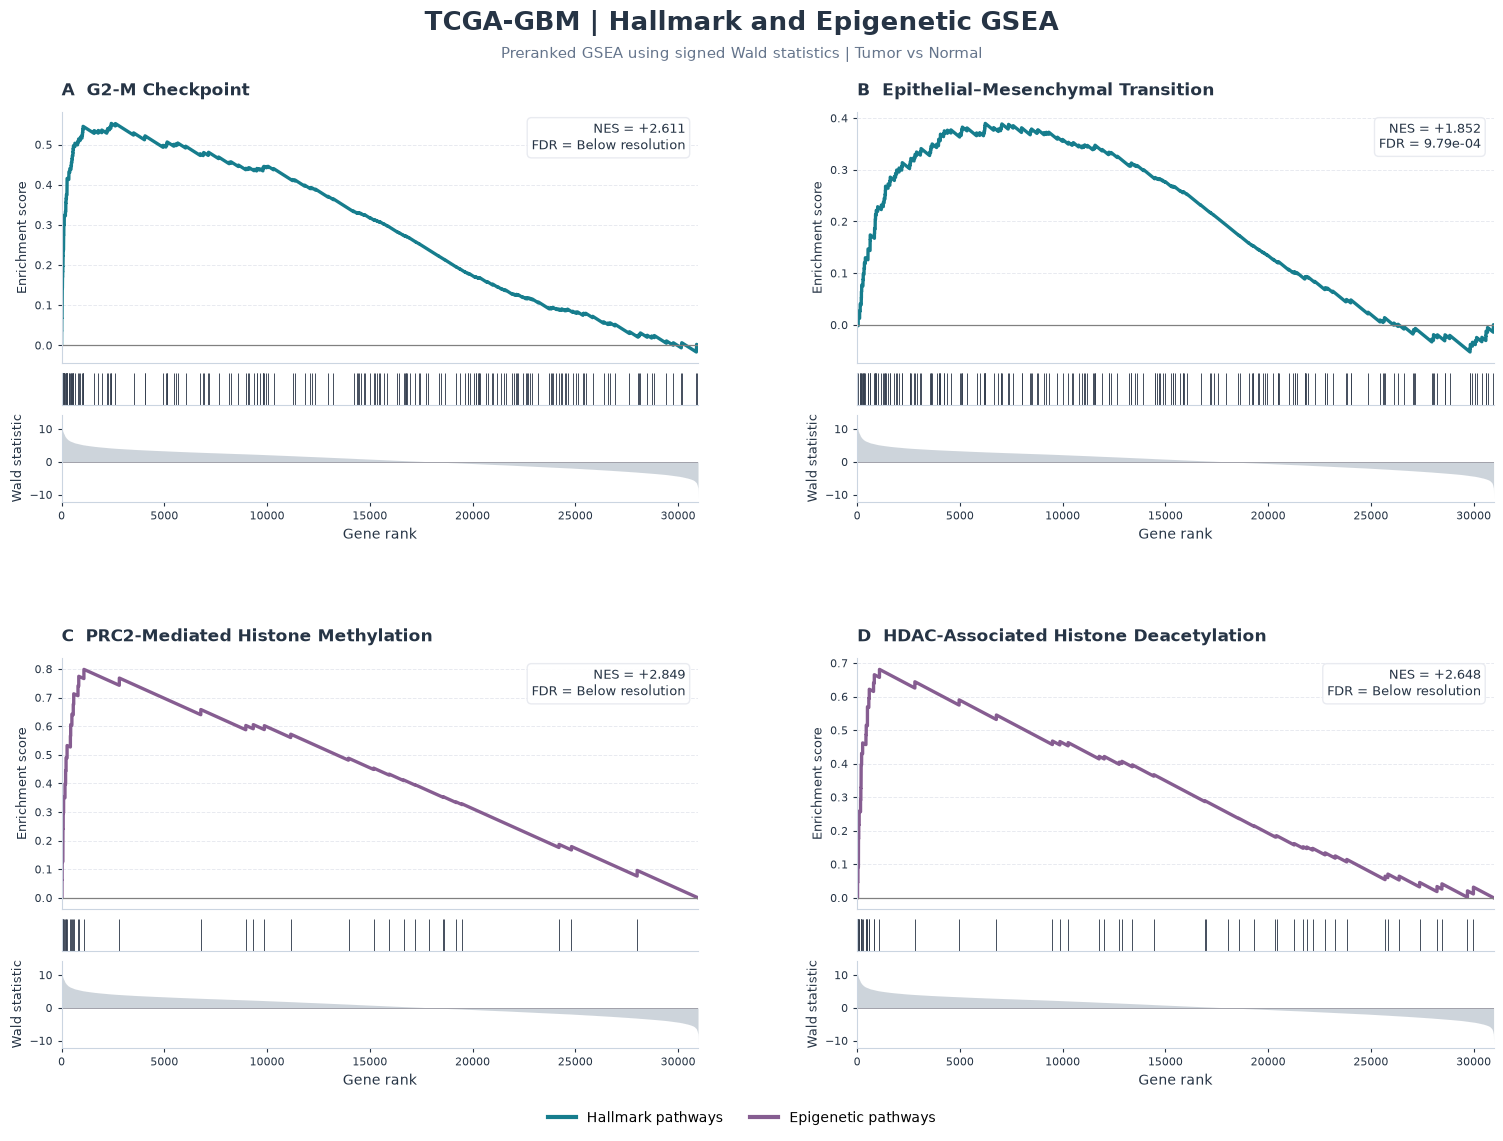

Saved PNG: /Users/olahassan/Desktop/Python/TCGA_GBM/results/figures/pathway_analysis/GSEA_Hallmark_Epigenetic_Multipanel.png
Saved PDF: /Users/olahassan/Desktop/Python/TCGA_GBM/results/figures/pathway_analysis/GSEA_Hallmark_Epigenetic_Multipanel.pdf


In [38]:
# Enhanced visulaization:

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D
from pathlib import Path

# ==========================================================
# 1. FIGURE SETTINGS
# ==========================================================

UP_COLOR = "#167D8D"       # Deep teal
EPI_COLOR = "#865D91"      # Muted plum
TEXT_COLOR = "#263445"
GRID_COLOR = "#E8EAF0"
HIT_COLOR = "#374151"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================================
# 2. SELECT PATHWAYS
# ==========================================================

def find_gsea_term(gsea_object, keyword):
    matches = [
        term for term in gsea_object.results
        if keyword.lower() in term.lower()
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected one match for '{keyword}', "
            f"found: {matches}"
        )

    return matches[0]


panels = [
    {
        "object": hallmark_gsea,
        "keyword": "G2-M Checkpoint",
        "title": "G2-M Checkpoint",
        "letter": "A",
        "color": UP_COLOR
    },
    {
        "object": hallmark_gsea,
        "keyword": "Epithelial Mesenchymal Transition",
        "title": "Epithelial–Mesenchymal Transition",
        "letter": "B",
        "color": UP_COLOR
    },
    {
        "object": epigenetic_gsea,
        "keyword": "PRC2 Methylates Histones",
        "title": "PRC2-Mediated Histone Methylation",
        "letter": "C",
        "color": EPI_COLOR
    },
    {
        "object": epigenetic_gsea,
        "keyword": "HDACs Deacetylate Histones",
        "title": "HDAC-Associated Histone Deacetylation",
        "letter": "D",
        "color": EPI_COLOR
    }
]

# ==========================================================
# 3. HELPER FUNCTIONS
# ==========================================================

def format_pvalue(value):
    value = float(value)

    if value == 0:
        return "Below resolution"

    if value < 0.001:
        return f"{value:.2e}"

    return f"{value:.3f}"


def get_gsea_data(gsea_object, keyword):

    term = find_gsea_term(gsea_object, keyword)
    result = gsea_object.results[term]

    # Stored running enrichment score
    running_es = np.asarray(
        result["RES"],
        dtype=float
    )

    # Gene positions in ranked list
    hit_positions = np.asarray(
        result["hits"],
        dtype=int
    )

    # Signed Wald statistics
    ranking = np.asarray(
        gsea_object.ranking,
        dtype=float
    )

    return {
        "term": term,
        "es": running_es,
        "hits": hit_positions,
        "ranking": ranking,
        "nes": float(result["nes"]),
        "pval": float(result["pval"]),
        "fdr": float(result["fdr"])
    }


def draw_gsea_panel(fig, subplot_spec, panel):

    data = get_gsea_data(
        panel["object"],
        panel["keyword"]
    )

    # Three vertically aligned axes per panel
    inner = GridSpecFromSubplotSpec(
        3, 1,
        subplot_spec=subplot_spec,
        height_ratios=[3.6, 0.45, 1.25],
        hspace=0.08
    )

    ax_es = fig.add_subplot(inner[0])
    ax_hits = fig.add_subplot(
        inner[1],
        sharex=ax_es
    )
    ax_rank = fig.add_subplot(
        inner[2],
        sharex=ax_es
    )

    x = np.arange(len(data["es"]))

    # ------------------------------------------------------
    # Running enrichment score
    # ------------------------------------------------------

    ax_es.plot(
        x,
        data["es"],
        color=panel["color"],
        linewidth=2.4
    )

    ax_es.axhline(
        0,
        color="#808080",
        linewidth=0.9
    )

    ax_es.set_ylabel(
        "Enrichment score",
        fontsize=9,
        color=TEXT_COLOR
    )

    ax_es.set_title(
        f'{panel["letter"]}  {panel["title"]}',
        loc="left",
        fontsize=12,
        fontweight="bold",
        color=TEXT_COLOR,
        pad=12
    )

    # Place statistics in an unobtrusive annotation box
    stats_text = (
        f'NES = {data["nes"]:+.3f}\n'
        f'FDR = {format_pvalue(data["fdr"])}'
    )

    ax_es.text(
        0.98,
        0.96,
        stats_text,
        transform=ax_es.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        color=TEXT_COLOR,
        bbox=dict(
            boxstyle="round,pad=0.35",
            facecolor="white",
            edgecolor=GRID_COLOR,
            alpha=0.95
        )
    )

    ax_es.grid(
        axis="y",
        color=GRID_COLOR,
        linestyle="--",
        linewidth=0.7
    )

    ax_es.set_axisbelow(True)

    # ------------------------------------------------------
    # Gene-set hit positions
    # ------------------------------------------------------

    ax_hits.vlines(
        data["hits"],
        0,
        1,
        color=HIT_COLOR,
        linewidth=0.65
    )

    ax_hits.set_ylim(0, 1)
    ax_hits.set_yticks([])
    ax_hits.set_ylabel("")

    # ------------------------------------------------------
    # Ranked Wald statistic
    # ------------------------------------------------------

    rank_x = np.arange(
        len(data["ranking"])
    )

    ax_rank.fill_between(
        rank_x,
        data["ranking"],
        0,
        color="#C5CDD5",
        alpha=0.85,
        linewidth=0
    )

    ax_rank.axhline(
        0,
        color="#A1A1AA",
        linewidth=0.7
    )

    ax_rank.set_ylabel(
        "Wald statistic",
        fontsize=9,
        color=TEXT_COLOR
    )

    ax_rank.set_xlabel(
        "Gene rank",
        fontsize=10,
        color=TEXT_COLOR
    )

    ax_rank.set_xlim(
        0,
        len(data["ranking"]) - 1
    )

    # ------------------------------------------------------
    # Formatting
    # ------------------------------------------------------

    for ax in [ax_es, ax_hits, ax_rank]:
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_color("#CBD5E1")
        ax.spines["bottom"].set_color("#CBD5E1")

        ax.tick_params(
            axis="both",
            labelsize=8,
            colors=TEXT_COLOR,
            length=3
        )

    ax_es.tick_params(
        axis="x",
        bottom=False,
        labelbottom=False
    )

    ax_hits.tick_params(
        axis="x",
        bottom=False,
        labelbottom=False
    )

    return data


# ==========================================================
# 4. CREATE 2 x 2 MULTIPANEL FIGURE
# ==========================================================

fig = plt.figure(
    figsize=(16, 12),
    facecolor="white"
)

outer = GridSpec(
    2, 2,
    figure=fig,
    left=0.075,
    right=0.97,
    bottom=0.10,
    top=0.88,
    wspace=0.25,
    hspace=0.40
)

for i, panel in enumerate(panels):

    row = i // 2
    col = i % 2

    draw_gsea_panel(
        fig,
        outer[row, col],
        panel
    )

fig.suptitle(
    "TCGA-GBM | Hallmark and Epigenetic GSEA",
    fontsize=19,
    fontweight="bold",
    color=TEXT_COLOR,
    y=0.965
)

fig.text(
    0.5,
    0.925,
    "Preranked GSEA using signed Wald statistics | Tumor vs Normal",
    ha="center",
    fontsize=11,
    color="#64748B"
)

legend_elements = [
    Line2D(
        [0], [0],
        color=UP_COLOR,
        lw=3,
        label="Hallmark pathways"
    ),
    Line2D(
        [0], [0],
        color=EPI_COLOR,
        lw=3,
        label="Epigenetic pathways"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.025),
    ncol=2,
    frameon=False,
    fontsize=10
)

# ==========================================================
# 5. SAVE FIGURE
# ==========================================================

png_path = (
    FIGURES_DIR /
    "GSEA_Hallmark_Epigenetic_Multipanel.png"
)

pdf_path = (
    FIGURES_DIR /
    "GSEA_Hallmark_Epigenetic_Multipanel.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()



**Figure: Hallmark and epigenetic gene set enrichment analysis in TCGA-GBM.**

Preranked gene set enrichment analysis (GSEA) was performed using signed Wald statistics derived from tumor-versus-normal differential gene expression analysis.

(A) G2-M checkpoint and (B) epithelial–mesenchymal transition show positive enrichment toward the tumor-associated end of the ranked transcriptome.

(C) PRC2-mediated histone methylation and (D) HDAC-associated histone deacetylation also exhibit positive enrichment.

The running enrichment score curves illustrate the distribution of pathway-associated genes across the ranked transcriptome. Vertical ticks indicate the positions of gene-set members, and the lower panels display the signed Wald statistic.

Positive normalized enrichment scores indicate enrichment toward genes with higher expression in GBM tumors.

The chromatin-associated enrichments should be interpreted in the context of shared canonical histone genes and do not directly demonstrate increased PRC2 or HDAC enzymatic activity.

NES: normalized enrichment score; FDR: false discovery rate.


## 6. Integrated Biological Interpretation and Conclusions

### 6.1 Overview

This study investigated transcriptional differences between glioblastoma (GBM) tumors and normal tissue using TCGA-derived RNA-seq data. Differential expression analysis was followed by Gene Ontology (GO) overrepresentation analysis, MSigDB Hallmark Gene Set Enrichment Analysis (GSEA), and targeted Reactome/GO enrichment analysis of chromatin-associated and epigenetic regulatory pathways.

Collectively, the analyses identified distinct transcriptional programs associated with **cell-cycle progression, neuronal function, mesenchymal-associated signaling, inflammation, and chromatin regulation**.

### 6.2 Cell-Cycle and Proliferation-Associated Transcriptional Programs

GO enrichment analysis of upregulated genes identified four significant biological processes (FDR < 0.05), all associated with mitotic spindle checkpoint regulation and chromosome segregation.

These pathways included key mitotic regulators such as PLK1, BUB1B, TTK, NDC80, and CDC20.

Hallmark GSEA independently supported these findings, revealing strong positive enrichment of:

- **G2-M Checkpoint:** NES = 2.61
- **E2F Targets:** NES = 2.49

Together, these results indicate that cell-cycle-associated transcriptional programs are strongly enriched in GBM tumors relative to normal tissue.

This pattern is consistent with the proliferative characteristics of GBM, although transcriptomic enrichment does not directly measure cell-cycle activity or proliferation rates.

### 6.3 Reduced Representation of Neuronal and Synaptic Transcriptional Programs

GO enrichment analysis of downregulated genes identified 429 significant biological processes (FDR < 0.05), predominantly associated with neuronal signaling and nervous system function.

The findings indicate reduced representation of mature neuronal and synaptic transcriptional programs in GBM tumor samples compared with normal tissue.

However, because bulk RNA-seq reflects the combined transcriptional profiles of multiple cell populations, these differences may be influenced by tissue cellular composition, including the relative abundance of differentiated neurons in normal brain tissue.

Consequently, the observed reduction in neuronal gene expression cannot be attributed exclusively to tumor-intrinsic transcriptional reprogramming.

### 6.4 Mesenchymal, Inflammatory, and Tumor-Associated Signaling

Hallmark GSEA revealed significant positive enrichment of several additional cancer-associated transcriptional programs:

| Hallmark pathway | NES | FDR |
|---|---:|---:|
| Epithelial–Mesenchymal Transition | +1.85 | 0.000979 |
| Interferon Gamma Response | +1.83 | 0.001102 |
| Interferon Alpha Response | +1.79 | 0.001175 |
| Angiogenesis | +1.73 | 0.002204 |
| IL-6/JAK/STAT3 Signaling | +1.66 | 0.004757 |
| Inflammatory Response | +1.47 | 0.027424 |

These findings suggest increased representation of mesenchymal-associated, inflammatory, and angiogenic transcriptional programs in GBM tissue.

The enrichment of EMT-associated genes is particularly relevant to GBM cellular plasticity and mesenchymal-like tumor states. 
Similarly, enrichment of inflammatory signaling may reflect contributions from tumor cells, infiltrating immune populations, or the surrounding tumor microenvironment.

### 6.5 Chromatin Remodeling and Epigenetic Regulatory Programs

Targeted GSEA of Reactome and GO chromatin-associated pathways identified significant enrichment of multiple gene sets involved in epigenetic regulation.

Among the strongest positively enriched pathways were:

| Epigenetic pathway | NES |
|---|---:|
| Deposition of new CENPA-containing nucleosomes | +3.01 |
| DNA Methylation (Reactome) | +2.99 |
| PRC2 Methylates Histones and DNA | +2.85 |
| HDACs Deacetylate Histones (Reactome) | +2.65 |
| Nucleosome Assembly (GO) | +2.17 |
| Nucleosome Organization (GO) | +1.99 |

These results indicate that genes annotated to chromatin organization, nucleosome assembly, histone modification, and epigenetic regulation are differentially represented across the GBM-associated transcriptome.

**Further analysis provided an important mechanistic distinction.**

Several positively enriched Reactome pathways shared canonical histone genes, including H2BC17, H2BC9, H2BC11, and H2AC20.

Their repeated contribution suggests that part of the observed epigenetic enrichment may reflect coordinated histone gene expression associated with DNA replication, nucleosome assembly, and cell-cycle progression.

Additional contributing genes included EZH2, ASF1B, HJURP, and CENPA, implicating transcriptional programs associated with Polycomb regulation, histone chaperoning, and centromeric chromatin organization.

Interestingly, Reactome HDAC-associated histone deacetylation showed positive enrichment (NES = +2.65), whereas the GO histone deacetylation pathway showed negative enrichment (NES = −2.04).The GO pathway included regulatory components such as HDAC5, HDAC11, CHD3, MTA1, and MTA3, contrasting with the substantial canonical histone contribution observed in the Reactome pathway.

Importantly, transcriptional enrichment of chromatin-associated pathways does not directly demonstrate changes in histone methylation, histone acetylation, chromatin accessibility, or epigenetic enzyme activity.

### 6.6 Relevance to HDAC7 and Epigenetic Therapeutic Research

The identification of chromatin-associated transcriptional signatures provides a biological context for investigating epigenetic regulatory mechanisms in GBM.

Of particular interest are pathways involving histone chaperoning, nucleosome organization, Polycomb-associated regulation, and histone deacetylation.These processes overlap conceptually with mechanisms investigated in HDAC7-focused research, including chromatin organization, histone variant regulation, and transcriptional plasticity.

However, **the present TCGA analysis does not establish HDAC7-specific regulatory activity or a causal relationship between HDAC7 and the enriched pathways**.
Integration with HDAC7 perturbation experiments and chromatin profiling would be necessary to establish mechanistic relationships.

### 6.7 Study Limitations and Future Directions

Several considerations are important when interpreting these findings.

**Bulk RNA-seq and cellular heterogeneity:** Differences between GBM and normal tissue may reflect both tumor-intrinsic transcriptional changes and differences in cell-type composition.

**Normal tissue comparability:** Interpretation depends on the origin and characteristics of the normal tissue samples, as well as potential technical and biological confounding between tumor and control cohorts.

**Transcription versus function:** RNA expression and GSEA cannot directly establish protein activity, chromatin modification abundance, or causal pathway regulation.

**Epigenetic pathway specificity:** Strong enrichment of canonical histone genes may contribute to the apparent enrichment of multiple chromatin-associated pathways, particularly in the presence of a prominent proliferation signature.

Future directions include:

1. Evaluating the contribution of canonical histone genes to chromatin-associated enrichment signatures.
2. Investigating HDAC7 expression in relation to GBM molecular heterogeneity and pathway activity.
3. Applying single-cell transcriptomic analysis to distinguish tumor-intrinsic signatures from tissue composition effects.
4. Integrating transcriptomic findings with ChIP-seq, CUT&Tag, or ATAC-seq to investigate chromatin-level regulation.
5. Exploring the relationship between epigenetic transcriptional signatures and potential therapeutic vulnerabilities.

### 6.8 Final Conclusion

This transcriptomic analysis identified **prominent cell-cycle, mesenchymal-associated, inflammatory, and chromatin-related transcriptional signatures in GBM tumors relative to normal tissue**, alongside reduced representation of neuronal and synaptic gene expression programs.

These results are hypothesis-generating and require cell-type-aware analyses and independent functional validation before drawing conclusions about specific epigenetic dependencies or therapeutic targets.